# 🌸 Iris Flower Classification

A machine learning project to classify iris flowers into three species — **Setosa**, **Versicolor**, and **Virginica** — based on four physical measurements: sepal length, sepal width, petal length, and petal width.

**Dataset:** The classic Iris dataset (150 samples, 3 balanced classes, no missing values), loaded via `sklearn.datasets.load_iris()`.

**Goal:** Compare multiple classification models, tune their key parameters, and evaluate performance beyond simple accuracy — using confusion matrices and classification reports to understand exactly where each model succeeds or fails.

**Models compared:** Decision Tree, K-Nearest Neighbors, Logistic Regression

In [1]:
import pandas as pd 
import numpy as np
from sklearn.datasets import load_iris
iris = load_iris()

In [2]:
from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()

df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
df.shape

(150, 6)

In [4]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [6]:
df['target'].value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

In [7]:
x = df.drop(columns=['target', 'species'])
y = df['target']

In [8]:
from sklearn.model_selection import train_test_split 
train_x ,test_x , train_y , test_y = train_test_split(x,y,test_size=0.2,random_state=4)

In [9]:
from sklearn.tree import DecisionTreeClassifier

In [10]:
tree = DecisionTreeClassifier()
tree

DecisionTreeClassifier()

In [11]:
tree.fit(train_x,train_y)

DecisionTreeClassifier()

In [48]:
y_hat_tree = tree.predict(test_x)

In [13]:
from sklearn import metrics


In [15]:
metrics.accuracy_score(test_y , y_hat)

0.9666666666666667

In [33]:
from sklearn.neighbors import KNeighborsClassifier

Ks = 10
mean_acc = np.zeros((Ks-1))
std_acc = np.zeros((Ks-1))

for n in range(1, Ks):
    neigh = KNeighborsClassifier(n_neighbors=n).fit(train_x, train_y)
    YhatKNN = neigh.predict(test_x)
    mean_acc[n-1] = metrics.accuracy_score(test_y, YhatKNN)
    std_acc[n-1] = np.std(YhatKNN == test_y) / np.sqrt(YhatKNN.shape[0])

best_n = mean_acc.argmax() + 1
print(f"بهترین مقدار K: {best_n} با دقت: {mean_acc.max()}")

بهترین مقدار K: 3 با دقت: 0.9666666666666667


In [34]:
from sklearn.linear_model import LogisticRegression

In [35]:
LR = LogisticRegression(C=1 , solver='liblinear').fit(train_x,train_y)
LR

LogisticRegression(C=1, solver='liblinear')

In [36]:
yhatLR = LR.predict(test_x)

In [37]:
from sklearn.metrics import jaccard_score 

In [38]:
metrics.accuracy_score(test_y, yhatLR)

0.9333333333333333

In [44]:
print('DecisionTreeClassifier :',metrics.accuracy_score(test_y , y_hat))
print('KNN',best_n,'mean_acc is : ',mean_acc.max())
print('LogisticRegression : ',metrics.accuracy_score(test_y, yhatLR))

DecisionTreeClassifier : 0.9666666666666667
KNN 3 mean_acc is :  0.9666666666666667
LogisticRegression :  0.9333333333333333


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       0.80      0.80      0.80         5
           2       0.89      0.89      0.89         9

    accuracy                           0.93        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.93      0.93      0.93        30



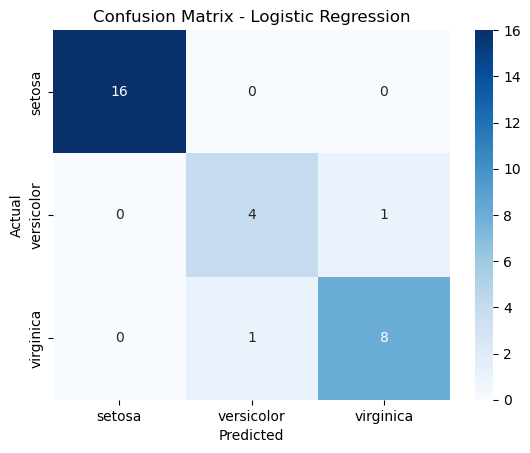

In [45]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Classification Report
print(classification_report(test_y, yhatLR))

# Confusion Matrix
cm = confusion_matrix(test_y, yhatLR)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['setosa','versicolor','virginica'],
            yticklabels=['setosa','versicolor','virginica'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       0.80      0.80      0.80         5
           2       0.89      0.89      0.89         9

    accuracy                           0.93        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.93      0.93      0.93        30



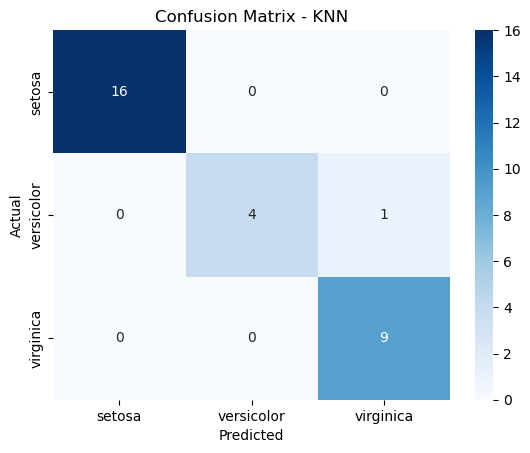

In [46]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Classification Report
print(classification_report(test_y, yhatLR))

# Confusion Matrix
cm = confusion_matrix(test_y, YhatKNN)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['setosa','versicolor','virginica'],
            yticklabels=['setosa','versicolor','virginica'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - KNN')
plt.show()

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       0.80      0.80      0.80         5
           2       0.89      0.89      0.89         9

    accuracy                           0.93        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.93      0.93      0.93        30



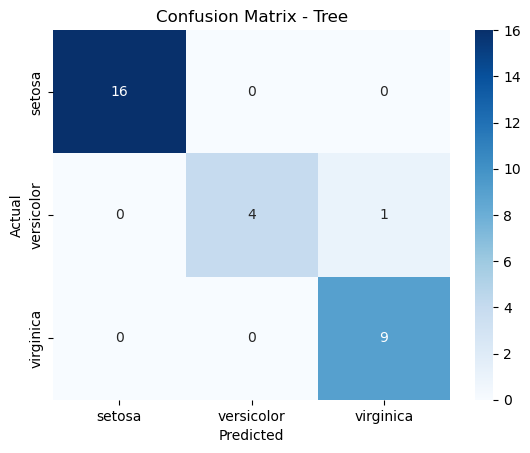

In [49]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Classification Report
print(classification_report(test_y, yhatLR))

# Confusion Matrix
cm = confusion_matrix(test_y, y_hat_tree)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['setosa','versicolor','virginica'],
            yticklabels=['setosa','versicolor','virginica'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Tree')
plt.show()

## 📌 Conclusion

| Model | Accuracy |
|---|---|
| Decision Tree Classifier | 0.967 |
| K-Nearest Neighbors (K=3) | 0.967 |
| Logistic Regression | 0.933 |

- **Decision Tree** and **KNN** slightly outperformed **Logistic Regression** on this test split.
- Most misclassifications occurred between **Versicolor** and **Virginica**, consistent with the feature overlap observed during EDA — Setosa remained perfectly separable across all models.
- Tuning mattered: increasing Logistic Regression's `C` from 0.01 to 1 improved its accuracy from 0.83 to 0.93, showing the importance of avoiding over-regularization.

### Next Steps
- Add PCA visualization to see class separability in 2D.
- Use cross-validation instead of a single train/test split for a more robust accuracy estimate.
- Explore feature importance for the Decision Tree model.